In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

np.random.seed(42)

n = 500

data = {
    "Visitor_ID": range(1, n + 1),
    "Traffic_Source": np.random.choice(
        ["Google", "Instagram", "LinkedIn", "Direct"],
        n
    ),
    "Service": np.random.choice(
        ["Internship", "Training", "IT Services", "Consulting"],
        n
    ),
    "City": np.random.choice(
        ["Guntur", "Vijayawada", "Hyderabad", "Chennai"],
        n
    ),
    "Age": np.random.randint(18, 40, n),
    "Inquiry": np.random.choice(
        ["Yes", "No"], n
    ),
    "Conversion": np.random.choice(
        ["Yes", "No"], n, p=[0.3, 0.7]
    ),
    "Revenue": np.random.randint(0, 10000, n)
}

df = pd.DataFrame(data)

df.head()


,Visitor_ID,Traffic_Source,Service,City,Age,Inquiry,Conversion,Revenue
0,1,LinkedIn,IT Services,Vijayawada,36,Yes,No,3537
1,2,Direct,Internship,Hyderabad,23,Yes,No,4558
2,3,Google,Internship,Guntur,23,No,No,6579
3,4,LinkedIn,Consulting,Guntur,20,Yes,No,8474
4,5,LinkedIn,IT Services,Guntur,24,Yes,No,9678


In [3]:

df.to_csv("veda_business_data.csv", index=False)

print("Dataset created successfully")


Dataset created successfully


In [4]:

df = pd.read_csv("veda_business_data.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())


   Visitor_ID Traffic_Source      Service        City  Age Inquiry Conversion  \
0           1       LinkedIn  IT Services  Vijayawada   36     Yes         No   
1           2         Direct   Internship   Hyderabad   23     Yes         No   
2           3         Google   Internship      Guntur   23      No         No   
3           4       LinkedIn   Consulting      Guntur   20     Yes         No   
4           5       LinkedIn  IT Services      Guntur   24     Yes         No   

   Revenue  
0     3537  
1     4558  
2     6579  
3     8474  
4     9678  
(500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Visitor_ID      500 non-null    int64 
 1   Traffic_Source  500 non-null    object
 2   Service         500 non-null    object
 3   City            500 non-null    object
 4   Age             500 non-null    int64 
 5   Inquiry  

In [5]:

print(df.isnull().sum())


Visitor_ID        0
Traffic_Source    0
Service           0
City              0
Age               0
Inquiry           0
Conversion        0
Revenue           0
dtype: int64


In [6]:

df = df.drop_duplicates()


In [7]:

print(df.dtypes)


Visitor_ID         int64
Traffic_Source    object
Service           object
City              object
Age                int64
Inquiry           object
Conversion        object
Revenue            int64
dtype: object


In [8]:

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())


Dataset shape: (500, 8)
Missing values: 0
Duplicates: 0


In [9]:

traffic = df["Traffic_Source"].value_counts()

print(traffic)


Traffic_Source
Direct       148
LinkedIn     122
Google       122
Instagram    108
Name: count, dtype: int64


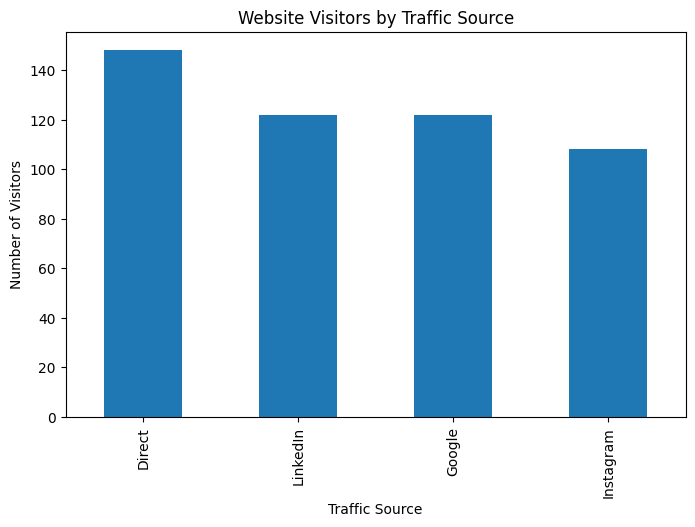

In [10]:

traffic.plot(kind="bar", figsize=(8,5))

plt.title("Website Visitors by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Visitors")
plt.show()


Service
Internship     136
Consulting     132
Training       122
IT Services    110
Name: count, dtype: int64


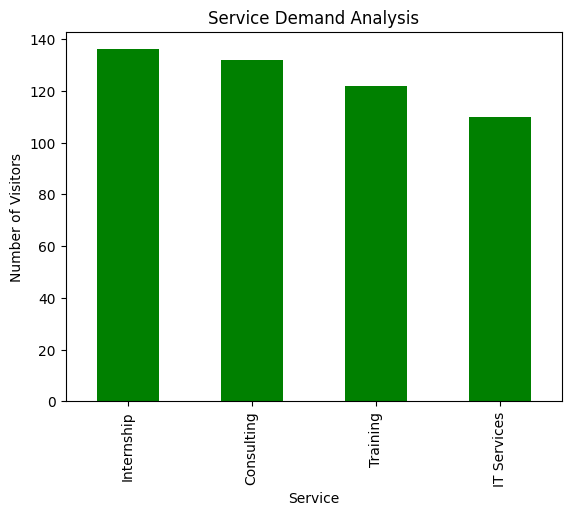

In [11]:

service_counts = df["Service"].value_counts()

print(service_counts)

service_counts.plot(kind="bar", color="green")

plt.title("Service Demand Analysis")
plt.xlabel("Service")
plt.ylabel("Number of Visitors")
plt.show()


Inquiry
No     260
Yes    240
Name: count, dtype: int64


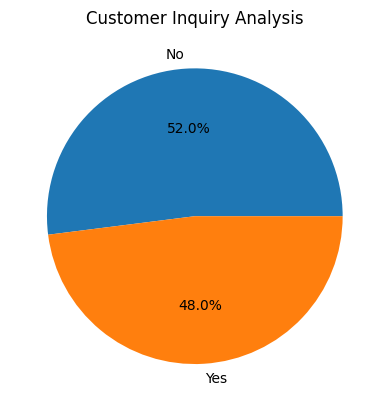

In [12]:

inquiries = df["Inquiry"].value_counts()

print(inquiries)

inquiries.plot(kind="pie", autopct="%1.1f%%")

plt.title("Customer Inquiry Analysis")
plt.ylabel("")
plt.show()


Service
Consulting     567401
IT Services    596896
Internship     742235
Training       546665
Name: Revenue, dtype: int64


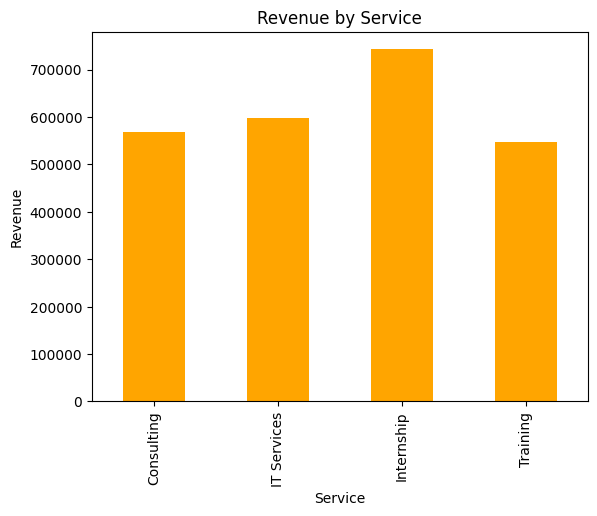

In [13]:

revenue = df.groupby("Service")["Revenue"].sum()

print(revenue)

revenue.plot(kind="bar", color="orange")

plt.title("Revenue by Service")
plt.xlabel("Service")
plt.ylabel("Revenue")
plt.show()


In [14]:

conversion_data = df.groupby(
    "Traffic_Source"
)["Conversion"].value_counts().unstack(fill_value=0)

print(conversion_data)


Conversion      No  Yes
Traffic_Source         
Direct          96   52
Google          87   35
Instagram       77   31
LinkedIn        87   35


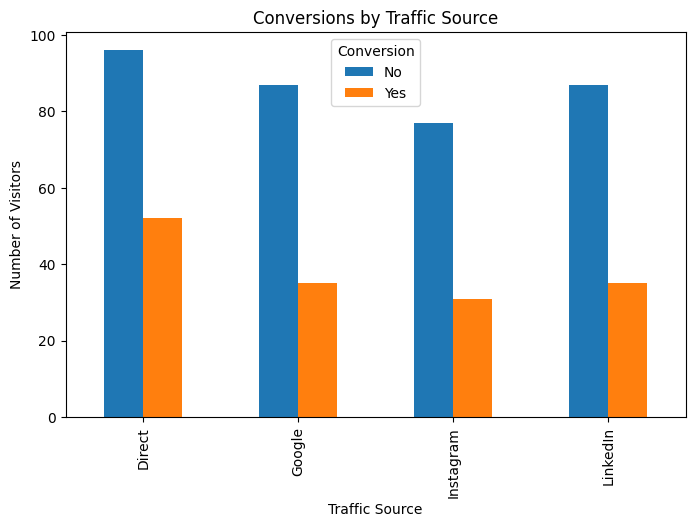

In [15]:

conversion_data.plot(kind="bar", figsize=(8,5))

plt.title("Conversions by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Visitors")
plt.show()


City
Vijayawada    136
Guntur        136
Hyderabad     127
Chennai       101
Name: count, dtype: int64


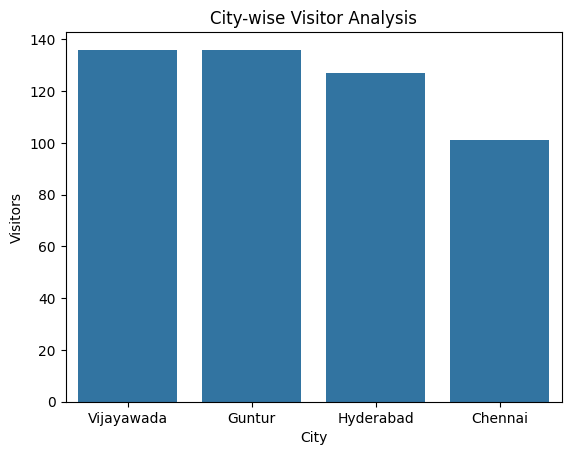

In [16]:

city_data = df["City"].value_counts()

print(city_data)

sns.barplot(x=city_data.index, y=city_data.values)

plt.title("City-wise Visitor Analysis")
plt.xlabel("City")
plt.ylabel("Visitors")
plt.show()


In [17]:

total_visitors = len(df)

total_inquiries = (df["Inquiry"] == "Yes").sum()

total_conversions = (df["Conversion"] == "Yes").sum()

total_revenue = df["Revenue"].sum()

conversion_rate = (
    total_conversions / total_visitors
) * 100

print("Total Visitors:", total_visitors)
print("Total Inquiries:", total_inquiries)
print("Total Conversions:", total_conversions)
print("Total Revenue:", total_revenue)
print("Conversion Rate:", round(conversion_rate, 2), "%")


Total Visitors: 500
Total Inquiries: 240
Total Conversions: 153
Total Revenue: 2453197
Conversion Rate: 30.6 %


In [18]:
from google.colab import files

files.download("veda_business_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

import os

os.makedirs("visualizations", exist_ok=True)

print("Visualizations folder created successfully!")


Visualizations folder created successfully!


In [21]:

plt.savefig("visualizations/traffic_analysis.png")

print("Graph saved successfully!")


Graph saved successfully!


<Figure size 640x480 with 0 Axes>

In [22]:

import os

print(os.listdir("visualizations"))


['traffic_analysis.png']


In [23]:

from google.colab import files

files.download("visualizations/traffic_analysis.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>